# 08_paper / figures.ipynb

**Purpose:** Curate every figure that goes into the paper. Produces:

1. A clean curated copy of all paper figures in `finalized_outputs/figures/`.
2. **Two new consolidated summary figures** that combine multiple existing plots into single hero images for the paper.
3. An `INDEX.md` describing every figure and where it appears in the paper.

**Inputs:** PNGs in `paper/figures/` (already produced by streams 01-05 and 07_eval).

**Outputs:**
- `finalized_outputs/figures/` — renamed, paper-ready PNGs
- `finalized_outputs/figures/INDEX.md` — figure descriptions
- Two new consolidated figures generated from existing data:
  - `headline_auroc_comparison.png` — single-panel "this is the result"
  - `gate_attribution_summary.png` — interpretability story in one figure

This notebook reads CSVs to regenerate two summary plots; existing per-stream/per-fold plots are copied as-is.


In [1]:
# === Imports & paths ===
from __future__ import annotations
import sys, shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 130
plt.rcParams["savefig.dpi"] = 200
plt.rcParams["font.size"] = 11

NB_DIR = Path.cwd()
ROOT = NB_DIR
for parent in [NB_DIR] + list(NB_DIR.parents):
    if (parent / "src" / "utils" / "paths.py").exists():
        ROOT = parent
        break
sys.path.insert(0, str(ROOT))

from src.utils.paths import PAPER, TABLES, FIGURES

FINAL = ROOT / "finalized_outputs"
FINAL_FIGS = FINAL / "figures"
FINAL_FIGS.mkdir(parents=True, exist_ok=True)

print("Repo root        :", ROOT)
print("paper/figures    :", FIGURES, "  exists:", FIGURES.exists())
print("Final figures dir:", FINAL_FIGS)
print()
print(f"Source figures   : {len(list(FIGURES.glob('*.png')))}")


Repo root        : e:\eve-rag
paper/figures    : E:\eve-rag\paper\figures   exists: True
Final figures dir: e:\eve-rag\finalized_outputs\figures

Source figures   : 49


## 1. Inventory all source figures

In [2]:
all_pngs = sorted(FIGURES.glob("*.png"))
print(f"Found {len(all_pngs)} PNGs in paper/figures/:")
for p in all_pngs:
    sz_kb = p.stat().st_size // 1024
    print(f"  {p.name:55s} {sz_kb:>5,} KB")


Found 49 PNGs in paper/figures/:
  ablations_auroc_grouped.png                                46 KB
  ablations_delta_heatmap.png                                61 KB
  all_streams_summary_bar.png                                86 KB
  cross_dataset_eval_auroc_bars.png                          49 KB
  cross_dataset_eval_f1_bars.png                             46 KB
  eda_caption_length_distribution.png                        53 KB
  eda_class_balance_processed.png                           120 KB
  eda_image_coverage_processed.png                          111 KB
  eda_mmfakebench_fake_cls_top20.png                         46 KB
  fusion_confusion_mmfakebench_test.png                      35 KB
  fusion_confusion_newsclippings_test.png                    39 KB
  fusion_confusion_verite_test.png                           33 KB
  fusion_gate_distribution.png                               69 KB
  fusion_roc_mmfakebench_test.png                            47 KB
  fusion_roc_newsclippings_te

## 2. Curate — copy paper-ready figures with clean names

In [3]:
# Map source filename → final filename. Order matters: tier-1 files come first.
CURATION = [
    # Tier-1: hero figures used in main paper
    ("ablations_auroc_grouped.png",                "01_ablations_auroc_grouped.png"),
    ("ablations_delta_heatmap.png",                "02_ablations_delta_heatmap.png"),
    ("cross_dataset_eval_auroc_bars.png",          "03_cross_dataset_auroc.png"),
    ("cross_dataset_eval_f1_bars.png",             "04_cross_dataset_f1.png"),
    ("newsclippings_eval_metric_bars.png",         "05_newsclippings_eval.png"),
    ("fusion_summary_bar.png",                     "06_fusion_summary.png"),
    ("fusion_gate_distribution.png",               "07_gate_distribution.png"),

    # Tier-2: confusion matrices and ROC curves (one per test set)
    ("fusion_confusion_newsclippings_test.png",    "08_confusion_NC.png"),
    ("fusion_confusion_mmfakebench_test.png",      "09_confusion_MMFB.png"),
    ("fusion_confusion_verite_test.png",           "10_confusion_VERITE.png"),
    ("fusion_roc_newsclippings_test.png",          "11_roc_NC.png"),
    ("fusion_roc_mmfakebench_test.png",            "12_roc_MMFB.png"),
    ("fusion_roc_verite_test.png",                 "13_roc_VERITE.png"),

    # Tier-3: qualitative montages
    ("qualitative_TP.png",                         "14_qualitative_TP.png"),
    ("qualitative_FP.png",                         "15_qualitative_FP.png"),
    ("qualitative_FN.png",                         "16_qualitative_FN.png"),
    ("qualitative_TN.png",                         "17_qualitative_TN.png"),

    # Tier-4: EDA / dataset descriptions
    ("eda_caption_length_distribution.png",        "18_eda_caption_length.png"),
    ("eda_class_balance_processed.png",            "19_eda_class_balance.png"),
    ("eda_image_coverage_processed.png",           "20_eda_image_coverage.png"),
    ("eda_mmfakebench_fake_cls_top20.png",         "21_eda_mmfb_fake_classes.png"),

    # Tier-5: per-stream summaries (appendix)
    ("stream_a_summary_bar.png",                   "22_stream_a_summary.png"),
    ("stream_b_summary_bar.png",                   "23_stream_b_summary.png"),
    ("stream_c_summary_bar.png",                   "24_stream_c_summary.png"),
    ("all_streams_summary_bar.png",                "25_all_streams_summary.png"),
]

for src_name, dst_name in CURATION:
    src = FIGURES / src_name
    dst = FINAL_FIGS / dst_name
    if src.exists():
        shutil.copy2(src, dst)
        print(f"  copied {src_name:55s} → {dst.name}")
    else:
        print(f"  [skip] {src_name}")

print()
print(f"Curated {len(list(FINAL_FIGS.glob('*.png')))} figures.")


  copied ablations_auroc_grouped.png                             → 01_ablations_auroc_grouped.png
  copied ablations_delta_heatmap.png                             → 02_ablations_delta_heatmap.png
  copied cross_dataset_eval_auroc_bars.png                       → 03_cross_dataset_auroc.png
  copied cross_dataset_eval_f1_bars.png                          → 04_cross_dataset_f1.png
  copied newsclippings_eval_metric_bars.png                      → 05_newsclippings_eval.png
  copied fusion_summary_bar.png                                  → 06_fusion_summary.png
  copied fusion_gate_distribution.png                            → 07_gate_distribution.png
  copied fusion_confusion_newsclippings_test.png                 → 08_confusion_NC.png
  copied fusion_confusion_mmfakebench_test.png                   → 09_confusion_MMFB.png
  copied fusion_confusion_verite_test.png                        → 10_confusion_VERITE.png
  copied fusion_roc_newsclippings_test.png                       → 11_roc_NC.p

## 3. NEW Hero figure — single-panel headline AUROC

Saved hero figure: e:\eve-rag\finalized_outputs\figures\00_HERO_auroc_comparison.png


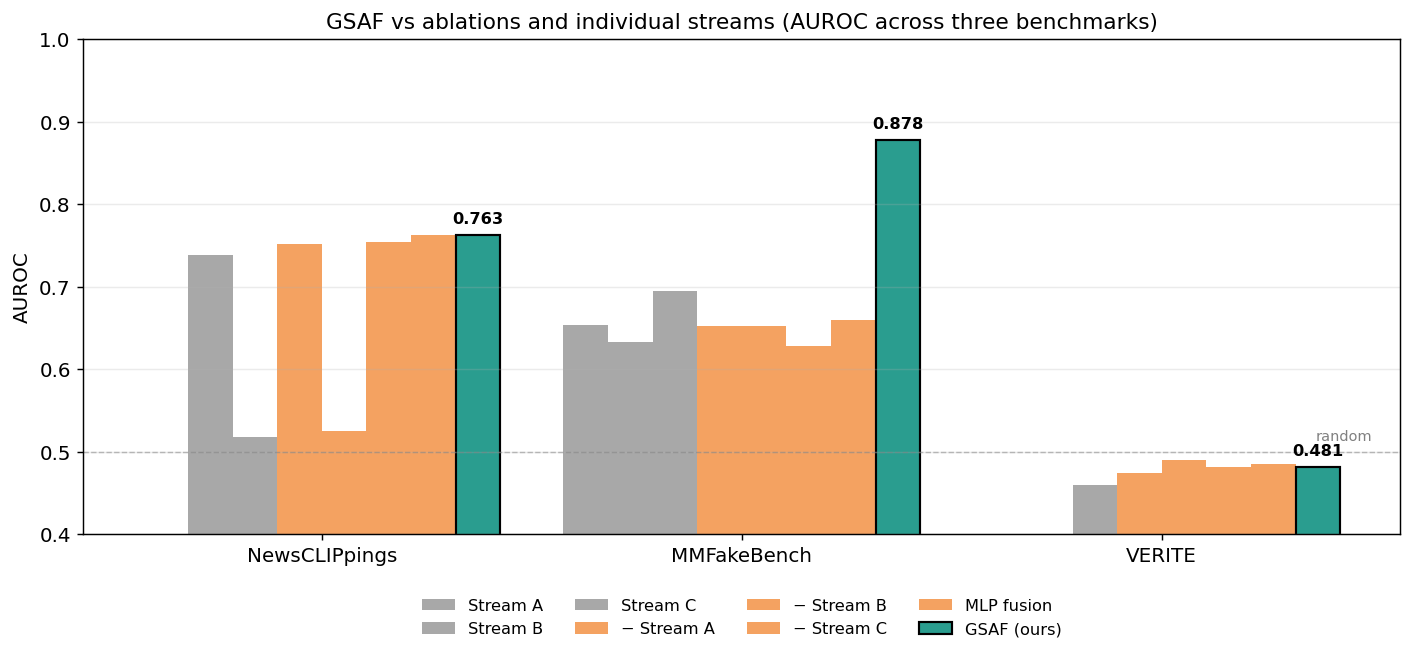

In [4]:
# Read the cross-dataset combined CSV and build a single panel showing
# GSAF (ours) vs ablations vs individual streams across all 3 datasets.
src = TABLES / "cross_dataset_eval_combined.csv"
df = pd.read_csv(src)

RENAME = {
    "GSAF (full)": "GSAF (ours)",
    "GSAF_default": "GSAF (ours)",
    "GSAF_no_a": "− Stream A",
    "GSAF_no_b": "− Stream B",
    "GSAF_no_c": "− Stream C",
    "GSAF_mlp_fusion": "MLP fusion",
    "Stream A (entities)": "Stream A",
    "Stream B (CLIP)": "Stream B",
    "Stream C (NLI)": "Stream C",
}
ORDER = ["Stream A", "Stream B", "Stream C", "− Stream A", "− Stream B", "− Stream C", "MLP fusion", "GSAF (ours)"]
COLOR = {
    "Stream A":   "#a8a8a8",
    "Stream B":   "#a8a8a8",
    "Stream C":   "#a8a8a8",
    "− Stream A": "#f4a261",
    "− Stream B": "#f4a261",
    "− Stream C": "#f4a261",
    "MLP fusion": "#f4a261",
    "GSAF (ours)":"#2a9d8f",
}

df["model"]   = df["model"].map(lambda x: RENAME.get(x, x))
df["dataset"] = df["dataset"].str.replace("-test", "")\
                                .str.replace("MMFakeBench", "MMFakeBench")\
                                .str.replace("VERITE", "VERITE")

# Add NewsCLIPpings test from cross_dataset CSV is missing; use newsclippings_eval.csv
nc_path = TABLES / "newsclippings_eval.csv"
if nc_path.exists():
    nc = pd.read_csv(nc_path)
    nc["model"]   = nc["model"].map(lambda x: RENAME.get(x, x))
    nc["dataset"] = "NewsCLIPpings"
    nc = nc[["model", "dataset", "auroc", "f1"]]
    df_full = pd.concat([df[["model","dataset","auroc","f1"]], nc], ignore_index=True)
else:
    df_full = df[["model","dataset","auroc","f1"]]

# Pivot: rows=model, cols=dataset
pivot = df_full.pivot_table(index="model", columns="dataset", values="auroc", aggfunc="first")
pivot = pivot.reindex([m for m in ORDER if m in pivot.index])

datasets = ["NewsCLIPpings", "MMFakeBench", "VERITE"]
datasets = [d for d in datasets if d in pivot.columns]

fig, ax = plt.subplots(figsize=(11, 5.2))
n_models  = len(pivot)
n_groups  = len(datasets)
group_w   = 0.85
bar_w     = group_w / n_models
xs        = np.arange(n_groups)

for i, model in enumerate(pivot.index):
    vals = [pivot.loc[model, d] if d in pivot.columns and not pd.isna(pivot.loc[model, d]) else 0 for d in datasets]
    offset = i * bar_w - group_w/2 + bar_w/2
    bars = ax.bar(xs + offset, vals, bar_w, label=model,
                  color=COLOR.get(model, "#aaa"),
                  edgecolor="black" if "GSAF (ours)" == model else "none",
                  linewidth=1.2 if "GSAF (ours)" == model else 0)
    # Value labels on the GSAF bars
    if model == "GSAF (ours)":
        for b, v in zip(bars, vals):
            if v > 0:
                ax.text(b.get_x() + b.get_width()/2, v + 0.01, f"{v:.3f}",
                        ha="center", va="bottom", fontsize=9, fontweight="bold")

ax.axhline(y=0.5, color="gray", linestyle="--", linewidth=0.8, alpha=0.5)
ax.text(n_groups - 0.5, 0.51, "random", color="gray", fontsize=8, va="bottom", ha="right")

ax.set_xticks(xs)
ax.set_xticklabels(datasets, fontsize=11)
ax.set_ylabel("AUROC")
ax.set_ylim(0.40, 1.00)
ax.set_title("GSAF vs ablations and individual streams (AUROC across three benchmarks)", fontsize=12)
ax.grid(axis="y", alpha=0.25)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.10), ncol=4, fontsize=9, frameon=False)
plt.tight_layout()

out = FINAL_FIGS / "00_HERO_auroc_comparison.png"
plt.savefig(out, bbox_inches="tight", dpi=200)
print(f"Saved hero figure: {out}")
plt.show()


## 4. NEW Interpretability figure — gate attribution + bucket

Gate attribution columns: ['dataset', '_bucket', 'A', 'B', 'C']
         dataset _bucket       A       B       C
0    mmfakebench      FN  0.3670  0.3819  0.2511
1    mmfakebench      FP  0.2082  0.2951  0.4967
2    mmfakebench      TN  0.1717  0.3988  0.4296
3    mmfakebench      TP  0.4646  0.1777  0.3577
4  newsclippings      FN  0.1972  0.5651  0.2377
Saved hero figure: e:\eve-rag\finalized_outputs\figures\00_HERO_gate_attribution.png


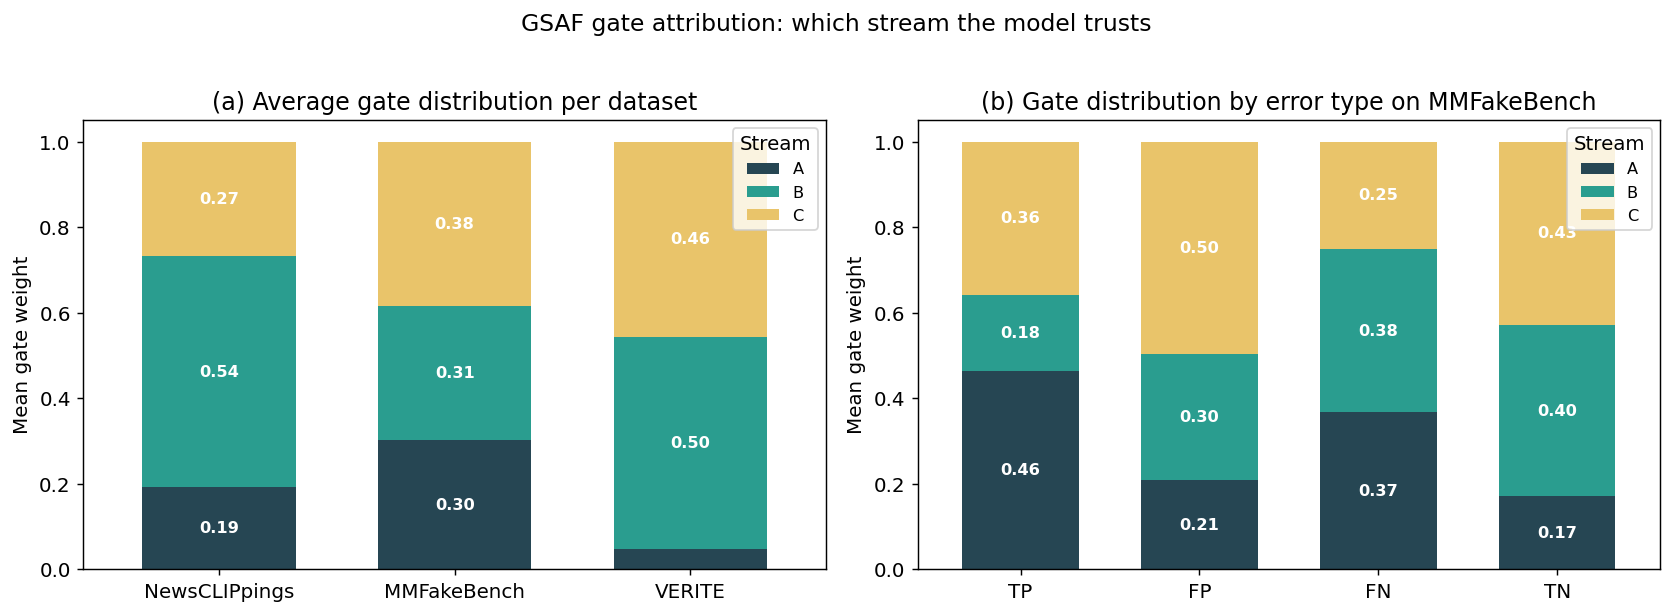

In [5]:
# Build a single-figure interpretability story:
# (a) Average gate weights per dataset
# (b) Gate weights per confusion-matrix bucket (TP/FP/FN/TN)
src = TABLES / "qualitative_gate_attribution.csv"
if not src.exists():
    print("Skipping — qualitative_gate_attribution.csv not found.")
else:
    gate_df = pd.read_csv(src)
    print("Gate attribution columns:", gate_df.columns.tolist())
    print(gate_df.head())

    # Standardize column names
    if "_dataset" in gate_df.columns:
        gate_df = gate_df.rename(columns={"_dataset": "dataset"})
    if "_bucket" in gate_df.columns:
        gate_df = gate_df.rename(columns={"_bucket": "bucket"})

    # Two-panel figure
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

    # --- (a) Mean gate per dataset (collapse over buckets) ---
    ax = axes[0]
    by_ds = gate_df.groupby("dataset")[["A", "B", "C"]].mean()
    by_ds = by_ds.reindex(["newsclippings", "mmfakebench", "verite"])
    by_ds.index = ["NewsCLIPpings", "MMFakeBench", "VERITE"]
    by_ds.plot(kind="bar", stacked=True, ax=ax,
               color=["#264653", "#2a9d8f", "#e9c46a"], width=0.65)
    ax.set_ylabel("Mean gate weight")
    ax.set_xlabel("")
    ax.set_title("(a) Average gate distribution per dataset")
    ax.set_xticklabels(by_ds.index, rotation=0)
    ax.legend(title="Stream", loc="upper right", fontsize=9)
    ax.set_ylim(0, 1.05)
    for i, idx in enumerate(by_ds.index):
        cum = 0
        for col, color in zip(["A","B","C"], ["#264653","#2a9d8f","#e9c46a"]):
            v = by_ds.loc[idx, col]
            if v > 0.05:
                ax.text(i, cum + v/2, f"{v:.2f}", ha="center", va="center",
                        fontsize=9, color="white", fontweight="bold")
            cum += v

    # --- (b) Gate per bucket on MMFakeBench (most interesting) ---
    ax = axes[1]
    sub = gate_df[gate_df["dataset"] == "mmfakebench"].set_index("bucket")[["A","B","C"]]
    sub = sub.reindex(["TP","FP","FN","TN"])
    sub.plot(kind="bar", stacked=True, ax=ax,
             color=["#264653","#2a9d8f","#e9c46a"], width=0.65)
    ax.set_ylabel("Mean gate weight")
    ax.set_xlabel("")
    ax.set_title("(b) Gate distribution by error type on MMFakeBench")
    ax.set_xticklabels(sub.index, rotation=0)
    ax.legend(title="Stream", loc="upper right", fontsize=9)
    ax.set_ylim(0, 1.05)
    for i, idx in enumerate(sub.index):
        cum = 0
        for col in ["A","B","C"]:
            v = sub.loc[idx, col]
            if v > 0.05:
                ax.text(i, cum + v/2, f"{v:.2f}", ha="center", va="center",
                        fontsize=9, color="white", fontweight="bold")
            cum += v

    plt.suptitle("GSAF gate attribution: which stream the model trusts", fontsize=13, y=1.02)
    plt.tight_layout()

    out = FINAL_FIGS / "00_HERO_gate_attribution.png"
    plt.savefig(out, bbox_inches="tight", dpi=200)
    print(f"Saved hero figure: {out}")
    plt.show()


## 5. NEW figure — Δ-AUROC heatmap (recoloured for paper)

Columns: ['model', 'dataset', 'Δauroc', 'Δauprc', 'Δaccuracy', 'Δf1', 'Δprecision', 'Δrecall']
Saved: e:\eve-rag\finalized_outputs\figures\00_HERO_ablation_delta.png


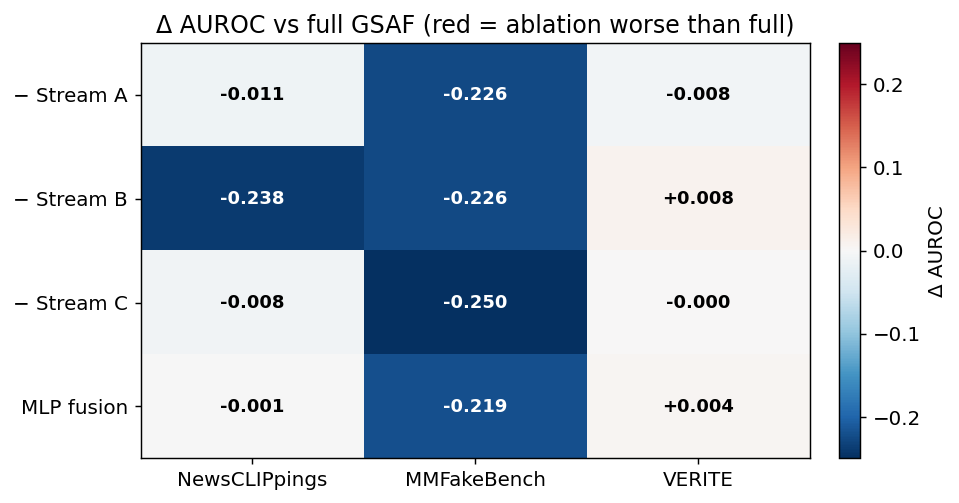

In [6]:
src = TABLES / "ablations_delta_vs_full.csv"
df = pd.read_csv(src)
print("Columns:", df.columns.tolist())

RENAME = {
    "GSAF_no_a": "− Stream A",
    "GSAF_no_b": "− Stream B",
    "GSAF_no_c": "− Stream C",
    "GSAF_mlp_fusion": "MLP fusion",
}
df["model"] = df["model"].map(lambda x: RENAME.get(x, x))
df["dataset"] = df["dataset"].str.replace("_test","")\
                                .str.replace("mmfakebench", "MMFakeBench")\
                                .str.replace("newsclippings", "NewsCLIPpings")\
                                .str.replace("verite", "VERITE")

heat = df.pivot_table(index="model", columns="dataset", values="Δauroc", aggfunc="first")
heat = heat.reindex(["− Stream A", "− Stream B", "− Stream C", "MLP fusion"])
heat = heat[["NewsCLIPpings", "MMFakeBench", "VERITE"]]

fig, ax = plt.subplots(figsize=(7.5, 4))
import matplotlib.colors as mcolors
vmax = max(0.05, abs(heat.values).max())
im = ax.imshow(heat.values, cmap="RdBu_r", vmin=-vmax, vmax=vmax, aspect="auto")
ax.set_xticks(range(heat.shape[1]))
ax.set_xticklabels(heat.columns)
ax.set_yticks(range(heat.shape[0]))
ax.set_yticklabels(heat.index)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.values[i, j]
        if not pd.isna(v):
            ax.text(j, i, f"{v:+.3f}",
                    ha="center", va="center",
                    color="black" if abs(v) < vmax*0.55 else "white",
                    fontsize=10, fontweight="bold")
ax.set_title("Δ AUROC vs full GSAF (red = ablation worse than full)")
fig.colorbar(im, ax=ax, fraction=0.04, pad=0.04, label="Δ AUROC")
plt.tight_layout()

out = FINAL_FIGS / "00_HERO_ablation_delta.png"
plt.savefig(out, bbox_inches="tight", dpi=200)
print(f"Saved: {out}")
plt.show()


## 6. Write figure INDEX.md

In [7]:
INDEX = '''# Finalized figures — INDEX

Three **HERO figures** (00_*) are newly generated by `08_paper/figures.ipynb` and are the most important visuals for the paper.

| # | File | Purpose | Used in |
|---|---|---|---|
| 00 | `00_HERO_auroc_comparison.png`   | One-panel hero — GSAF beats every ablation across 3 benchmarks                | Main results §5 (Fig 1) |
| 00 | `00_HERO_gate_attribution.png`   | Two-panel interpretability story — gate weights per dataset and error type   | Discussion §6 (Fig 2) |
| 00 | `00_HERO_ablation_delta.png`     | Compact Δ-AUROC heatmap                                                       | Ablation §5 (Fig 3) |

### Tier-1 paper figures

| # | File | Purpose | Used in |
|---|---|---|---|
| 01 | `01_ablations_auroc_grouped.png`  | Grouped AUROC bars across all 5 model variants × 3 datasets   | §5 |
| 02 | `02_ablations_delta_heatmap.png`  | Original Δ heatmap (8-bit colour version)                     | §5 |
| 03 | `03_cross_dataset_auroc.png`      | OOD cross-dataset AUROC                                       | §5 |
| 04 | `04_cross_dataset_f1.png`         | OOD cross-dataset F1                                          | §5 |
| 05 | `05_newsclippings_eval.png`       | In-distribution NewsCLIPpings metrics                          | §5 |
| 06 | `06_fusion_summary.png`           | Summary bar across all training metrics                        | §5 |
| 07 | `07_gate_distribution.png`        | Gate-weight density per stream                                 | §6 |

### Tier-2 confusion matrices and ROC curves

| # | File | Purpose | Used in |
|---|---|---|---|
| 08 | `08_confusion_NC.png` | NewsCLIPpings test confusion | Appendix |
| 09 | `09_confusion_MMFB.png` | MMFakeBench confusion | Appendix |
| 10 | `10_confusion_VERITE.png` | VERITE confusion | Appendix |
| 11–13 | `11_roc_NC.png`, `12_roc_MMFB.png`, `13_roc_VERITE.png` | Per-dataset ROC | Appendix |

### Tier-3 qualitative montages

| # | File | Purpose | Used in |
|---|---|---|---|
| 14–17 | `14_qualitative_TP.png` … `17_qualitative_TN.png` | 4 montages, one per confusion bucket | Discussion §6 |

### Tier-4 EDA & dataset description

| # | File | Purpose | Used in |
|---|---|---|---|
| 18 | `18_eda_caption_length.png`     | Caption length distribution                | §3 |
| 19 | `19_eda_class_balance.png`      | Class balance per dataset                  | §3 |
| 20 | `20_eda_image_coverage.png`     | Image-availability per dataset             | §3 |
| 21 | `21_eda_mmfb_fake_classes.png`  | MMFakeBench fake-class breakdown           | §3 |

### Tier-5 per-stream appendix figures

| # | File | Purpose | Used in |
|---|---|---|---|
| 22 | `22_stream_a_summary.png` | Stream A standalone results | Appendix |
| 23 | `23_stream_b_summary.png` | Stream B standalone results | Appendix |
| 24 | `24_stream_c_summary.png` | Stream C standalone results | Appendix |
| 25 | `25_all_streams_summary.png` | All-streams overview | Appendix |
'''
(FINAL_FIGS / "INDEX.md").write_text(INDEX, encoding="utf-8")
print("Wrote INDEX.md")


Wrote INDEX.md


## 7. Final summary

In [8]:
print("="*70)
print(" FINAL FIGURES COMPLETE")
print("="*70)
print(f"  finalized_outputs/figures/ : {len(list(FINAL_FIGS.glob('*.png')))} PNGs + INDEX.md")
print()
print("Hero figures (the 3 most important):")
for p in sorted(FINAL_FIGS.glob("00_HERO_*.png")):
    print(f"  → {p.name}")
print()
print("Next steps:")
print("  - Build the 3 draw.io diagrams (architecture, data pipeline, system flow)")
print("  - Update GRAND_PLAN.md with everything we did")


 FINAL FIGURES COMPLETE
  finalized_outputs/figures/ : 28 PNGs + INDEX.md

Hero figures (the 3 most important):
  → 00_HERO_ablation_delta.png
  → 00_HERO_auroc_comparison.png
  → 00_HERO_gate_attribution.png

Next steps:
  - Build the 3 draw.io diagrams (architecture, data pipeline, system flow)
  - Update GRAND_PLAN.md with everything we did
